# Sweep 1: hyperparameters vs evaluation metrics

Sweep `sweep1_rowlasso_d_lambda_gamma/` (code `main @ 9cd81e3`, run 2026-10-28/29): the current model
(lasso per row, shared V, row-weighted negatives, JD start, 4-statistics head, binary label swaps),
trained on **two disjoint halves of the perturbations** (half seed 0), seed 0 on each half, 1000 epochs,
epoch kept by validation ROC AUC.

| hyperparameter | values |
|---|---|
| d | 10, 15, 20 |
| λ | ×0.5, ×1, ×2, ×4 the per-row scale (median \|z\| of least-squares activities on the JD axes: 0.0154 / 0.0138 / 0.0129 for d = 10 / 15 / 20) |
| γ (gene prior) | 0, 0.05, 0.15 (γ = 0 also turns the hinge off; otherwise τ = 0.5, μ = 100) |

36 settings × 2 halves = 72 models. Each setting gives **one** cross-half comparison (half-0 model vs
half-1 model). Seed noise on one such value is about ±0.015 (from 9 seed pairs at d = 20, λ ×2.1, γ 0.05),
so differences below ~0.03 are not differences.

**Metrics** (per setting unless noted)
- *agreement*: matched |cos| (Hungarian) between the two halves' programs, mean over the d programs; *ax09 / ax08*: how many matched programs exceed 0.9 / 0.8; *frac09*: ax09 / d.
- *start*: the same agreement for the JD starting axes; *gain* = agreement − start (what training adds).
- *jaccard*: overlap of the matched programs' gene sets (genes carrying 80 % of a program's squared weight).
- *val AUC*, *val accuracy*, *programs per row*: mean of the two halves at the selected epoch.
- *max |cos|*, *genes80*: distinctness and sparsity of a model's own programs.
- *selected epoch*: the epoch with the best validation AUC (per model).
- *test AUC*: only if the test set has been read for these models (see the last section).

In [1]:
import glob, json, re, itertools
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr

D = Path('/large_storage/ctc/beraslan/ModuleFinder/sweep1_rowlasso_d_lambda_gamma')
SCALE = {10: 0.0154, 15: 0.0138, 20: 0.0129}          # per-row lambda scale per d

# chart styling: validated categorical palette (one hue per d, fixed order) + a marker per d
D_COLOR = {10: '#2a78d6', 15: '#eb6834', 20: '#1baf7a'}
D_MARK = {10: 'o', 15: 's', 20: '^'}
INK, INK2, GRID = '#1f1f1e', '#5f5e5a', '#e6e5e0'
plt.rcParams.update({'figure.dpi': 110, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
                     'legend.frameon': False, 'lines.linewidth': 2, 'lines.markersize': 7})

## 1. Load the models

In [2]:
u = lambda A: A / np.linalg.norm(np.asarray(A, np.float64), axis=1, keepdims=True)

def matched(A, B):
    C = np.abs(u(A) @ u(B).T); r, c = linear_sum_assignment(-C); return C[r, c], r, c

def genesets80(B):
    out = []
    for w in u(B) ** 2:
        o = np.argsort(-w); out.append(set(o[:int(np.searchsorted(np.cumsum(w[o]), 0.8) + 1)]))
    return out

models = []
for f in sorted(D.glob('config_*.json')):
    c = json.loads(f.read_text()); tag = c['tag']
    h = pd.read_csv(D / f'history_{tag}.csv'); v = h.dropna(subset=['val_auc'])
    b = v.loc[v.val_auc.idxmax()]
    B = np.load(D / f'B_{tag}.npy')
    with np.load(D / f'B_evals_{tag}.npz') as z:
        start = z['B'][0]
    Bu = u(B)
    models.append(dict(tag=tag, d=c['n_factors'], lam=c['lasso_lambda'], lam_x=round(c['lasso_lambda'] / SCALE[c['n_factors']], 2),
                       gamma=c['gene_sparsity'], half=int(re.search(r'_half(\d)', tag).group(1)),
                       epochs_trained=len(h), selected_epoch=int(c['selected_epoch']), final_epoch=int(c['final_epoch']),
                       val_auc=b.val_auc, val_auc_final=v.iloc[-1].val_auc, val_accuracy=b.val_accuracy,
                       programs_per_row=b.val_programs_per_pair, val_disc=b.val_disc_objective,
                       max_cos=float((np.abs(Bu @ Bu.T) - np.eye(len(Bu))).max()),
                       genes80=float(np.median([len(s) for s in genesets80(B)])), B=B, start=start))
M = pd.DataFrame(models)
print(len(M), 'models;', 'epochs trained:', M.epochs_trained.value_counts().to_dict(),
      '| last epoch index:', M.final_epoch.value_counts().to_dict())

72 models; epochs trained: {1000: 72} | last epoch index: {999: 72}


## 2. One row per setting: cross-half agreement and the rest

In [3]:
rows = []
for (d, lam_x, g), grp in M.groupby(['d', 'lam_x', 'gamma']):
    a, b = grp[grp.half == 0].iloc[0], grp[grp.half == 1].iloc[0]
    x, r, c = matched(a.B, b.B); s, _, _ = matched(a.start, b.start)
    SA, SB = genesets80(a.B), genesets80(b.B)
    rows.append(dict(d=d, lam_x=lam_x, lam=a.lam, gamma=g,
                     agreement=x.mean(), ax09=int((x > 0.9).sum()), ax08=int((x > 0.8).sum()), frac09=(x > 0.9).mean(),
                     start=s.mean(), gain=x.mean() - s.mean(),
                     jaccard=np.mean([len(SA[i] & SB[j]) / len(SA[i] | SB[j]) for i, j in zip(r, c)]),
                     val_auc=grp.val_auc.mean(), val_accuracy=grp.val_accuracy.mean(),
                     programs_per_row=grp.programs_per_row.mean(), max_cos=grp.max_cos.mean(),
                     genes80=grp.genes80.mean(), selected_epoch_mean=grp.selected_epoch.mean()))
S = pd.DataFrame(rows).sort_values(['gamma', 'd', 'lam_x']).reset_index(drop=True)
S.to_csv(D / 'analysis_sweep1_settings.csv', index=False)
S.round(3)

,d,lam_x,lam,gamma,agreement,ax09,ax08,frac09,start,gain,jaccard,val_auc,val_accuracy,programs_per_row,max_cos,genes80,selected_epoch_mean
0,10,0.5,0.008,0.00,0.891,7,9,0.700,0.870,0.021,0.629,0.820,0.746,4.958,0.584,777.50,702.0
1,10,1.0,0.015,0.00,0.943,8,10,0.800,0.871,0.072,0.720,0.800,0.725,3.081,0.471,765.50,783.0
2,10,2.0,0.031,0.00,0.957,8,10,0.800,0.873,0.085,0.737,0.765,0.693,1.876,0.561,728.00,697.5
3,10,4.0,0.062,0.00,0.941,9,10,0.900,0.873,0.068,0.690,0.715,0.651,1.092,0.585,686.50,867.0
4,15,0.5,0.007,0.00,0.806,6,8,0.400,0.838,-0.032,0.530,0.835,0.759,7.645,0.610,743.00,775.5
5,15,1.0,0.014,0.00,0.777,4,8,0.267,0.839,-0.061,0.492,0.819,0.743,4.922,0.422,745.50,847.5
6,15,2.0,0.028,0.00,0.813,6,10,0.400,0.839,-0.026,0.511,0.785,0.710,2.957,0.504,710.00,837.0
7,15,4.0,0.055,0.00,0.761,5,9,0.333,0.838,-0.077,0.489,0.737,0.668,1.712,0.558,709.00,732.0
8,20,0.5,0.006,0.00,0.635,4,6,0.200,0.749,-0.114,0.402,0.844,0.767,10.465,0.599,724.00,970.5
9,20,1.0,0.013,0.00,0.694,3,6,0.150,0.749,-0.055,0.404,0.828,0.754,6.705,0.470,716.75,846.0


## 3. Agreement vs validation AUC

The central trade-off: does a model that discriminates better also reproduce its programs across
disjoint perturbations? One panel per γ; colour and marker = d; labels = λ multiplier.

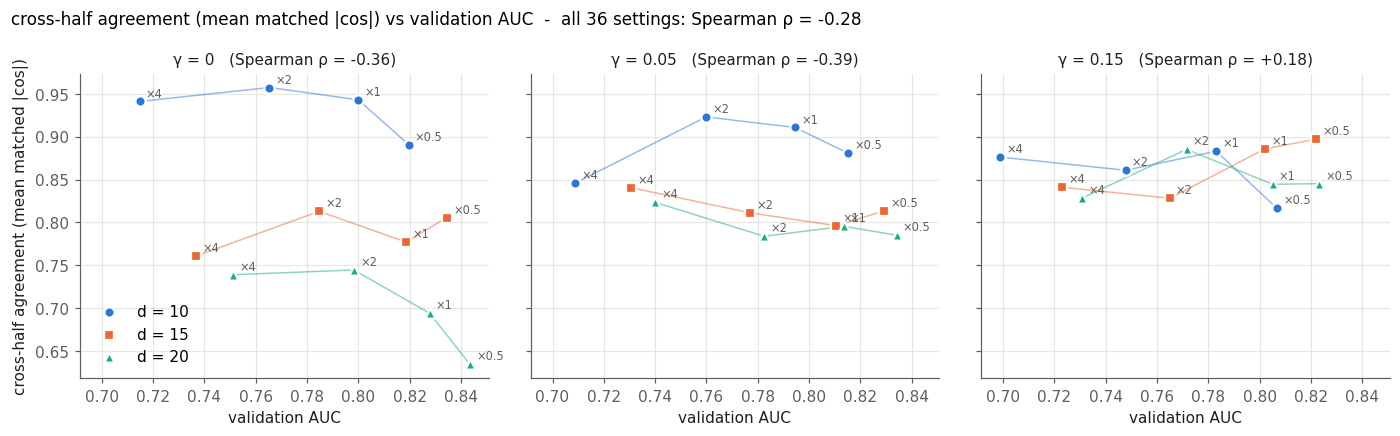

In [4]:
def scatter_by_gamma(ycol, ylabel, xcol='val_auc', xlabel='validation AUC'):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
    for ax, g in zip(axes, sorted(S.gamma.unique())):
        sub = S[S.gamma == g]
        for d in (10, 15, 20):
            t = sub[sub.d == d].sort_values('lam_x')
            ax.plot(t[xcol], t[ycol], color=D_COLOR[d], lw=1, alpha=0.5)
            ax.scatter(t[xcol], t[ycol], color=D_COLOR[d], marker=D_MARK[d], s=46, edgecolor='white', linewidth=1.5,
                       zorder=3, label=f'd = {d}')
            for _, rr in t.iterrows():
                ax.annotate(f"×{rr.lam_x:g}", (rr[xcol], rr[ycol]), xytext=(4, 3), textcoords='offset points',
                            fontsize=7.5, color=INK2)
        rho = spearmanr(sub[xcol], sub[ycol]).statistic
        ax.set_title(f'γ = {g:g}   (Spearman ρ = {rho:+.2f})', fontsize=10, color=INK)
        ax.set_xlabel(xlabel)
    axes[0].set_ylabel(ylabel); axes[0].legend(loc='lower left')
    rho_all = spearmanr(S[xcol], S[ycol]).statistic
    fig.suptitle(f'{ylabel} vs {xlabel}  -  all 36 settings: Spearman ρ = {rho_all:+.2f}', x=0.01, ha='left', fontsize=11)
    fig.tight_layout(); plt.show()

scatter_by_gamma('agreement', 'cross-half agreement (mean matched |cos|)')

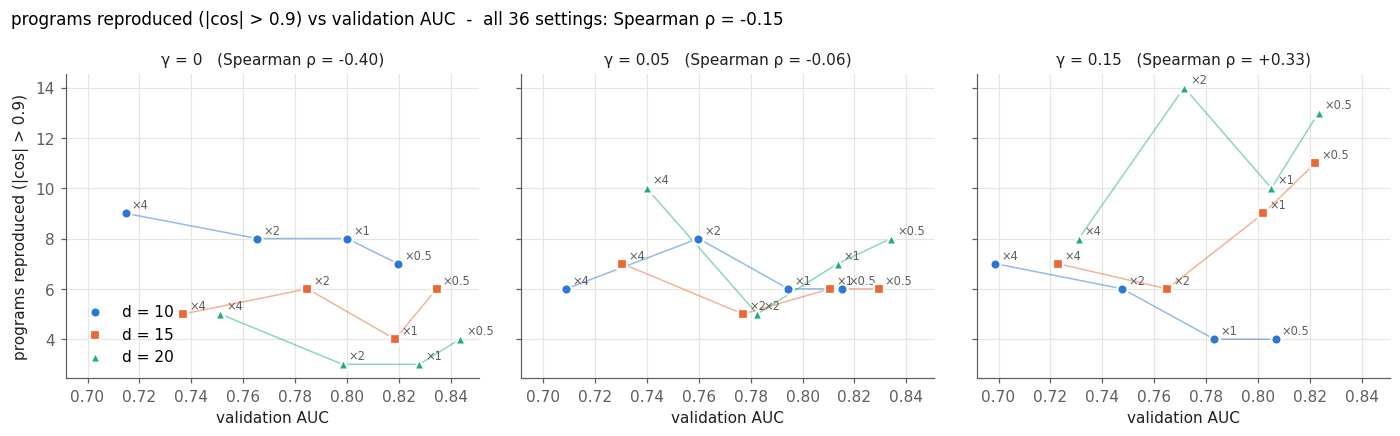

In [5]:
scatter_by_gamma('ax09', 'programs reproduced (|cos| > 0.9)')

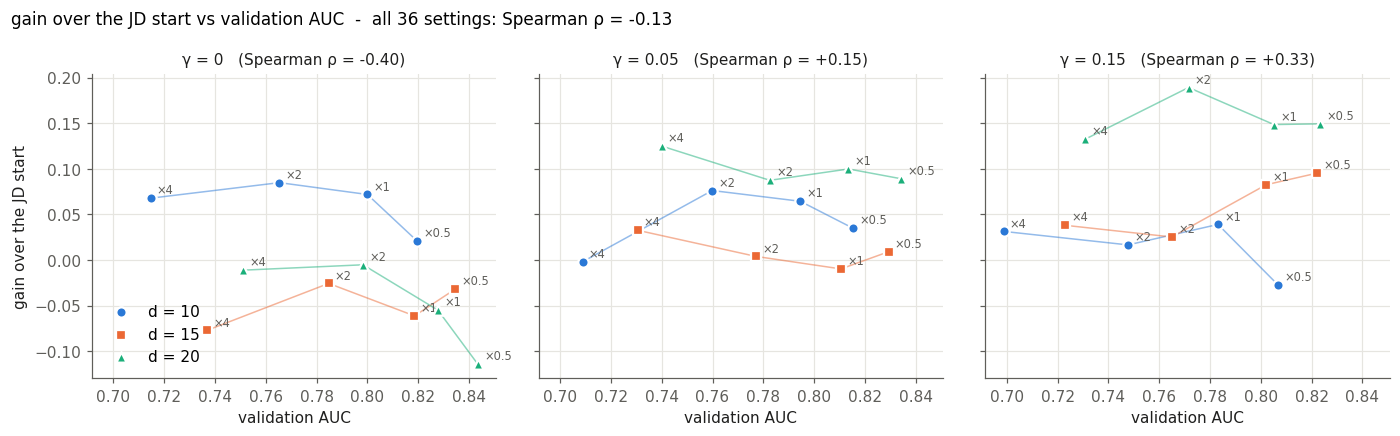

In [6]:
scatter_by_gamma('gain', 'gain over the JD start')

Mean agreement is not comparable across d: fewer components are more stable from the start
(JD start ≈ 0.87 at d = 10 vs ≈ 0.70 at d = 20). The number of reproduced programs and the gain
over the start compare d more fairly.

## 4. Each metric against λ, per d and γ

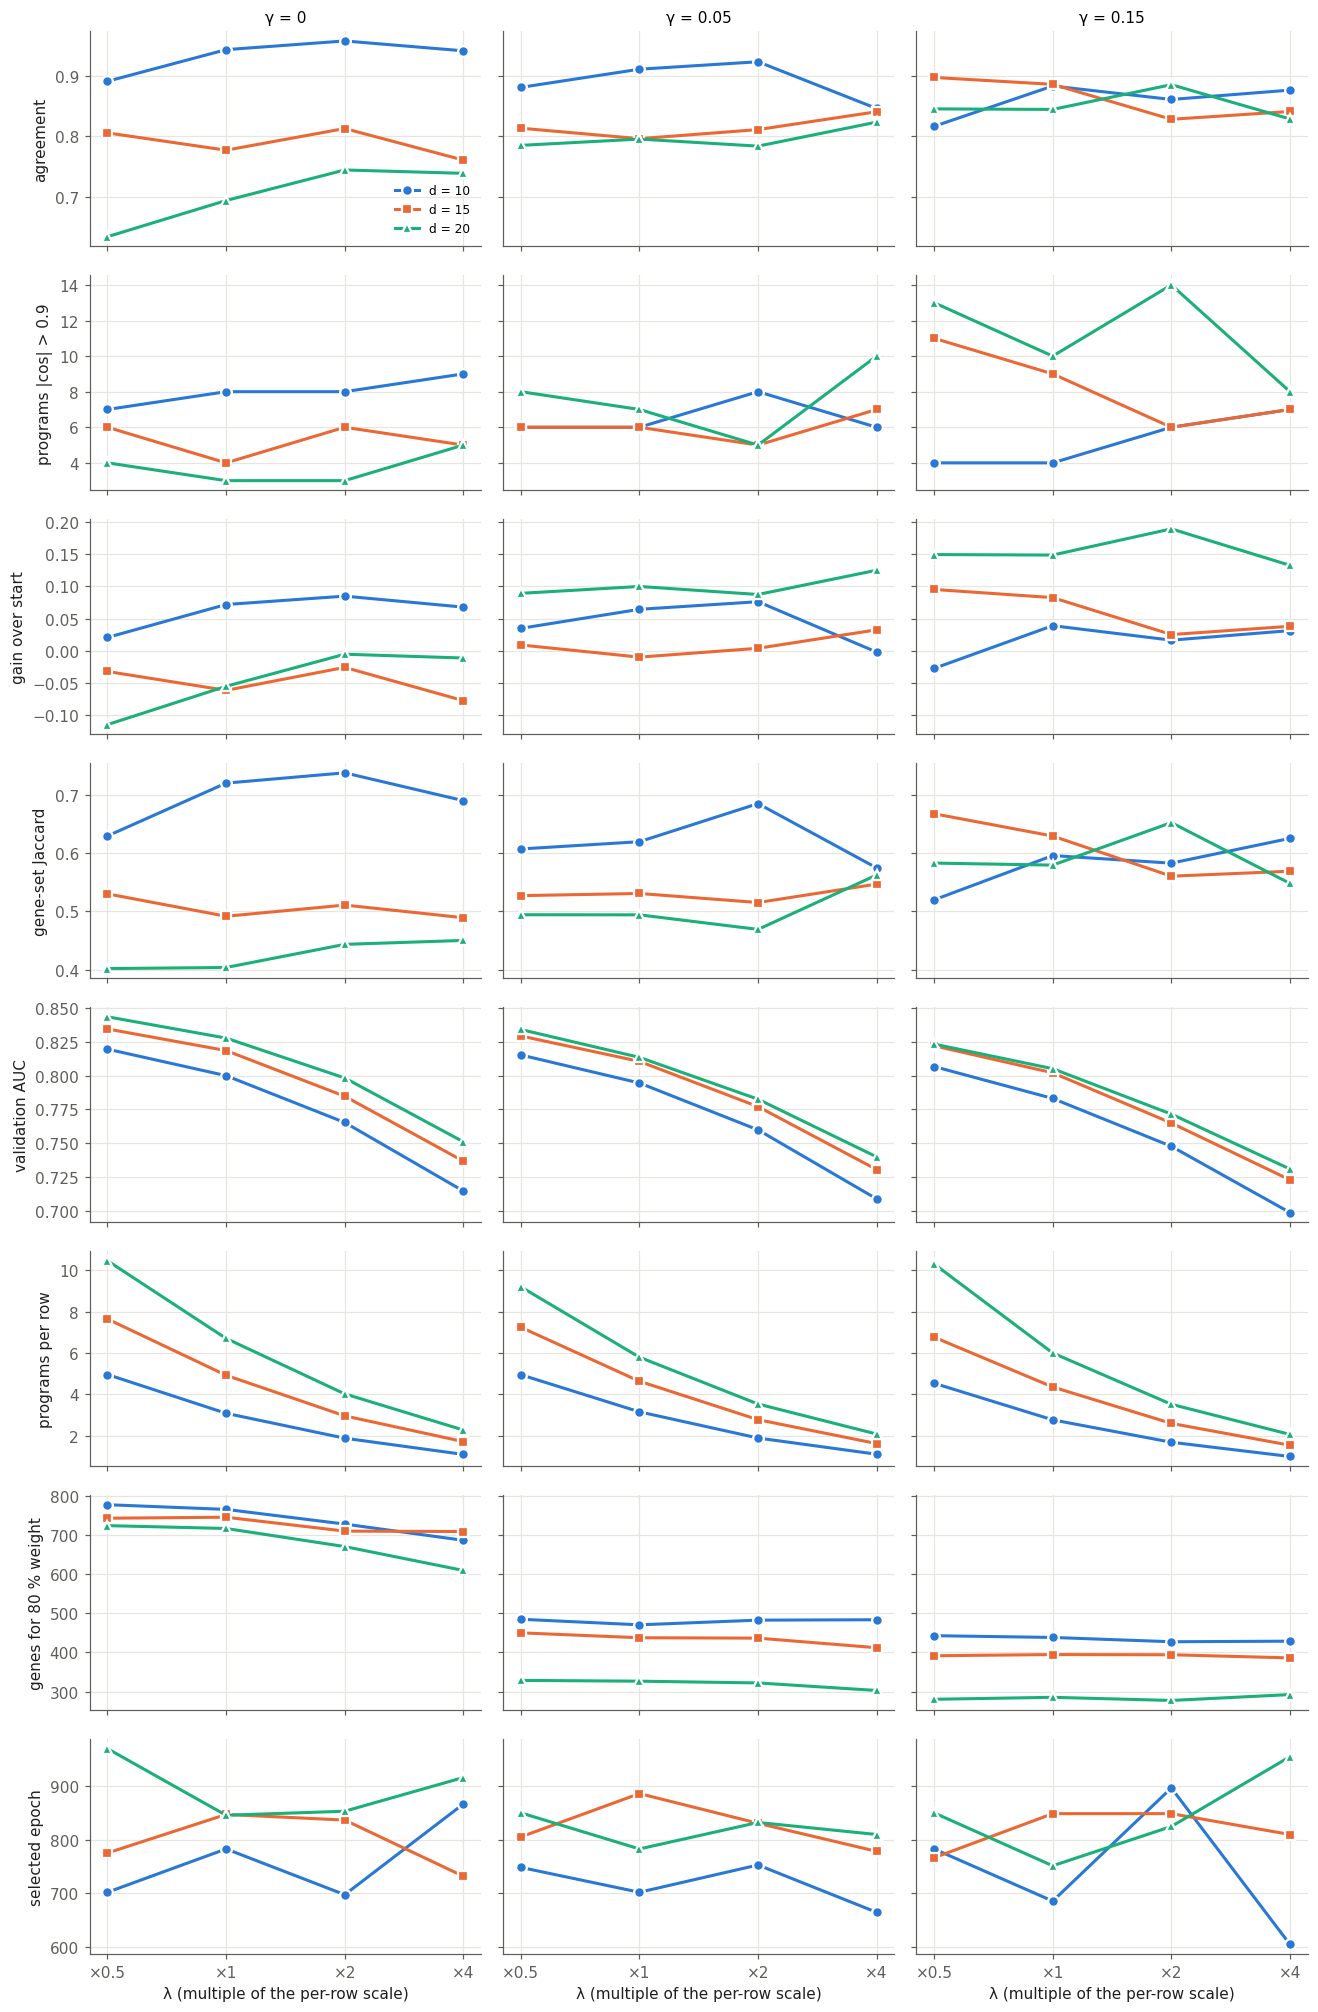

In [7]:
metrics = [('agreement', 'agreement'), ('ax09', 'programs |cos| > 0.9'), ('gain', 'gain over start'),
           ('jaccard', 'gene-set Jaccard'), ('val_auc', 'validation AUC'), ('programs_per_row', 'programs per row'),
           ('genes80', 'genes for 80 % weight'), ('selected_epoch_mean', 'selected epoch')]
fig, axes = plt.subplots(len(metrics), 3, figsize=(12, 2.3 * len(metrics)), sharex=True, sharey='row')
for j, g in enumerate(sorted(S.gamma.unique())):
    for i, (m, lab) in enumerate(metrics):
        ax = axes[i, j]
        for d in (10, 15, 20):
            t = S[(S.gamma == g) & (S.d == d)].sort_values('lam_x')
            ax.plot(t.lam_x, t[m], color=D_COLOR[d], marker=D_MARK[d], markeredgecolor='white', markeredgewidth=1.5,
                    label=f'd = {d}')
        ax.set_xscale('log', base=2); ax.set_xticks([0.5, 1, 2, 4], ['×0.5', '×1', '×2', '×4'])
        if j == 0: ax.set_ylabel(lab)
        if i == 0: ax.set_title(f'γ = {g:g}', fontsize=10)
        if i == len(metrics) - 1: ax.set_xlabel('λ (multiple of the per-row scale)')
axes[0, 0].legend(loc='best', fontsize=8)
fig.tight_layout(); plt.show()

## 5. How the metrics correlate (Spearman, over the 36 settings)

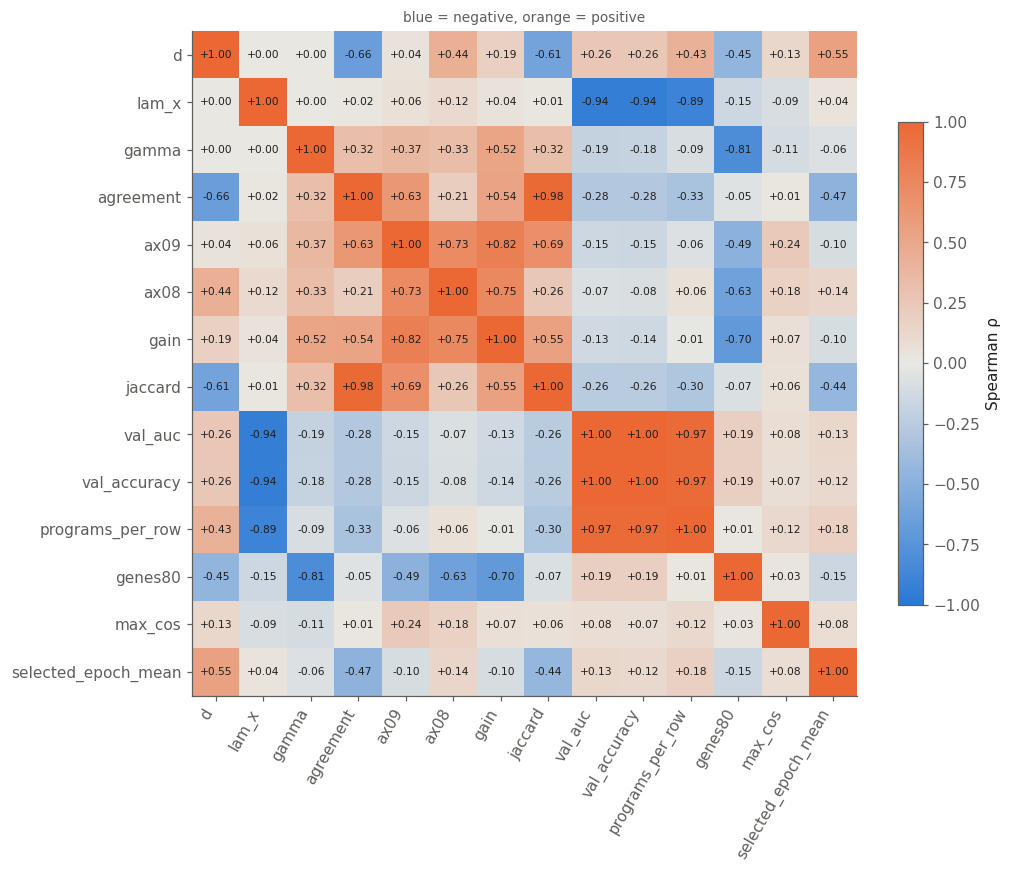

,d,lam_x,gamma,agreement,ax09,ax08,gain,jaccard,val_auc,val_accuracy,programs_per_row,genes80,max_cos,selected_epoch_mean
d,1.00,0.00,0.00,-0.66,0.04,0.44,0.19,-0.61,0.26,0.26,0.43,-0.45,0.13,0.55
lam_x,0.00,1.00,0.00,0.02,0.06,0.12,0.04,0.01,-0.94,-0.94,-0.89,-0.15,-0.09,0.04
gamma,0.00,0.00,1.00,0.32,0.37,0.33,0.52,0.32,-0.19,-0.18,-0.09,-0.81,-0.11,-0.06
agreement,-0.66,0.02,0.32,1.00,0.63,0.21,0.54,0.98,-0.28,-0.28,-0.33,-0.05,0.01,-0.47
ax09,0.04,0.06,0.37,0.63,1.00,0.73,0.82,0.69,-0.15,-0.15,-0.06,-0.49,0.24,-0.10
ax08,0.44,0.12,0.33,0.21,0.73,1.00,0.75,0.26,-0.07,-0.08,0.06,-0.63,0.18,0.14
gain,0.19,0.04,0.52,0.54,0.82,0.75,1.00,0.55,-0.13,-0.14,-0.01,-0.70,0.07,-0.10
jaccard,-0.61,0.01,0.32,0.98,0.69,0.26,0.55,1.00,-0.26,-0.26,-0.30,-0.07,0.06,-0.44
val_auc,0.26,-0.94,-0.19,-0.28,-0.15,-0.07,-0.13,-0.26,1.00,1.00,0.97,0.19,0.08,0.13
val_accuracy,0.26,-0.94,-0.18,-0.28,-0.15,-0.08,-0.14,-0.26,1.00,1.00,0.97,0.19,0.07,0.12


In [8]:
cols = ['d', 'lam_x', 'gamma', 'agreement', 'ax09', 'ax08', 'gain', 'jaccard', 'val_auc', 'val_accuracy',
        'programs_per_row', 'genes80', 'max_cos', 'selected_epoch_mean']
corr = S[cols].corr(method='spearman')
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#e9e8e3', '#eb6834'])   # blue - neutral grey - orange
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha='right'); ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:+.2f}', ha='center', va='center', fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman ρ'); ax.set_title('blue = negative, orange = positive', fontsize=9, color=INK2)
fig.tight_layout(); plt.show()
corr.round(2)

Within each d (the cross-d comparison of mean agreement is confounded by the start):

In [9]:
within = pd.DataFrame({d: S[S.d == d][['agreement', 'ax09', 'gain', 'jaccard', 'programs_per_row', 'lam_x', 'gamma']]
                          .corrwith(S[S.d == d].val_auc, method='spearman') for d in (10, 15, 20)})
within.columns = [f'd = {d}' for d in within.columns]; within.index.name = 'ρ with val AUC'
within.round(2)

,d = 10,d = 15,d = 20
ρ with val AUC,,,
agreement,0.10,-0.13,-0.37
ax09,-0.26,-0.05,-0.29
gain,-0.03,-0.15,-0.37
jaccard,-0.01,-0.04,-0.36
programs_per_row,0.98,1.00,0.97
lam_x,-0.97,-0.97,-0.95
gamma,-0.24,-0.24,-0.30


## 6. Agreement vs gene-set Jaccard, and sparsity vs AUC

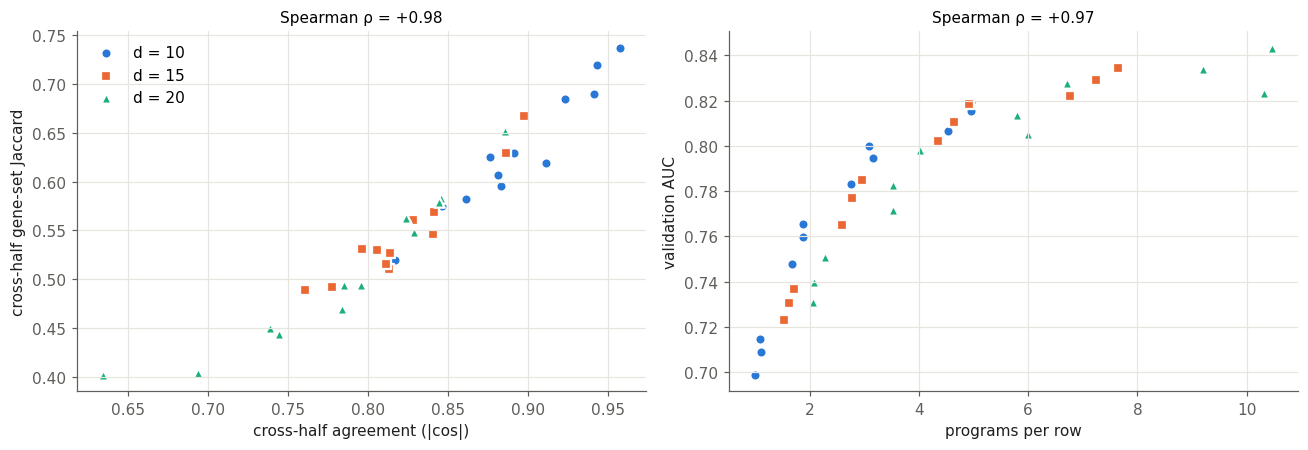

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for d in (10, 15, 20):
    t = S[S.d == d]
    axes[0].scatter(t.agreement, t.jaccard, color=D_COLOR[d], marker=D_MARK[d], s=46, edgecolor='white', linewidth=1.5, label=f'd = {d}')
    axes[1].scatter(t.programs_per_row, t.val_auc, color=D_COLOR[d], marker=D_MARK[d], s=46, edgecolor='white', linewidth=1.5, label=f'd = {d}')
axes[0].set_xlabel('cross-half agreement (|cos|)'); axes[0].set_ylabel('cross-half gene-set Jaccard')
axes[0].set_title(f'Spearman ρ = {spearmanr(S.agreement, S.jaccard).statistic:+.2f}', fontsize=10)
axes[1].set_xlabel('programs per row'); axes[1].set_ylabel('validation AUC')
axes[1].set_title(f'Spearman ρ = {spearmanr(S.programs_per_row, S.val_auc).statistic:+.2f}', fontsize=10)
axes[0].legend(); fig.tight_layout(); plt.show()

## 7. Training length and the selected epoch

Every model trains all 1000 epochs (no early stopping); the kept checkpoint is the epoch with the
best validation AUC, evaluated every 3 epochs.

epochs trained per model: {1000: 72}
selected epoch: median 789 | range 453 - 999 | >= 900: 23 of 72


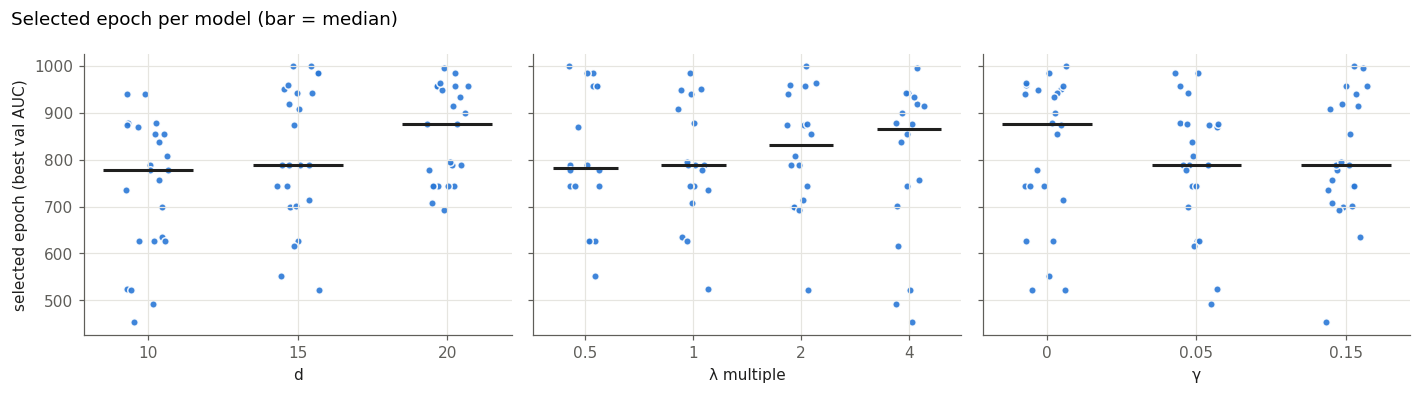

Validation AUC at the selected epoch vs at epoch 1000: mean difference 0.0065 (max 0.0128)


In [11]:
print('epochs trained per model:', M.epochs_trained.value_counts().to_dict())
print('selected epoch: median', int(M.selected_epoch.median()), '| range', M.selected_epoch.min(), '-', M.selected_epoch.max(),
      '| >= 900:', int((M.selected_epoch >= 900).sum()), 'of', len(M))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (col, lab) in zip(axes, [('d', 'd'), ('lam_x', 'λ multiple'), ('gamma', 'γ')]):
    levels = sorted(M[col].unique())
    for k, lv in enumerate(levels):
        y = M[M[col] == lv].selected_epoch.to_numpy()
        ax.scatter(np.full(len(y), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(y)), y,
                   color='#2a78d6', s=24, edgecolor='white', linewidth=1, alpha=0.9)
        ax.hlines(np.median(y), k - 0.3, k + 0.3, color=INK, lw=2)
    ax.set_xticks(range(len(levels)), [f'{lv:g}' for lv in levels]); ax.set_xlabel(lab)
axes[0].set_ylabel('selected epoch (best val AUC)'); fig.suptitle('Selected epoch per model (bar = median)', x=0.01, ha='left')
fig.tight_layout(); plt.show()
print('Validation AUC at the selected epoch vs at epoch 1000: mean difference',
      f"{(M.val_auc - M.val_auc_final).mean():.4f} (max {(M.val_auc - M.val_auc_final).max():.4f})")

In [12]:
M[['d', 'lam_x', 'gamma', 'half', 'epochs_trained', 'selected_epoch', 'val_auc', 'val_auc_final', 'programs_per_row']] \
    .sort_values(['gamma', 'd', 'lam_x', 'half']).round(3).reset_index(drop=True)

,d,lam_x,gamma,half,epochs_trained,selected_epoch,val_auc,val_auc_final,programs_per_row
0,10,0.5,0.00,0,1000,627,0.819,0.809,4.883
1,10,0.5,0.00,1,1000,777,0.820,0.816,5.034
2,10,1.0,0.00,0,1000,627,0.800,0.790,3.022
3,10,1.0,0.00,1,1000,939,0.800,0.797,3.141
4,10,2.0,0.00,0,1000,873,0.760,0.750,1.811
...,...,...,...,...,...,...,...,...,...
67,20,1.0,0.15,1,1000,708,0.810,0.805,6.080
68,20,2.0,0.15,0,1000,693,0.768,0.762,3.518
69,20,2.0,0.15,1,1000,957,0.775,0.773,3.517
70,20,4.0,0.15,0,1000,996,0.723,0.714,1.979


## 8. Test set

The test pairs were read once for all 72 models (`scripts/read_test.py`, read #1 in `TEST_READS.log`,
2026-10-29, at the user's request for this notebook). Each half model is scored on the test pairs of the
perturbations it was trained on (about 1,500 pairs, 12.5-13.4k rows per half), at the epoch chosen on
validation; wrong labels are drawn as in validation. **Nothing here is used to choose settings**: that is
done on validation and cross-half agreement alone, otherwise the test numbers stop being an unbiased
estimate.

In [13]:
T = pd.read_csv(D / 'test_scores_sweep1.csv')
MT = M.merge(T, on='tag')
print(len(MT), 'models with a test read; test pairs per model', MT.test_pairs.min(), '-', MT.test_pairs.max())
ST = S.merge(MT.groupby(['d', 'lam_x', 'gamma'])[['test_auc', 'test_accuracy', 'test_programs_per_pair']].mean()
             .reset_index(), on=['d', 'lam_x', 'gamma'])
ST['val_minus_test_auc'] = ST.val_auc - ST.test_auc
ST.to_csv(D / 'analysis_sweep1_settings_with_test.csv', index=False)
ST[['d', 'lam_x', 'gamma', 'agreement', 'ax09', 'ax08', 'jaccard', 'val_auc', 'test_auc', 'val_minus_test_auc',
    'programs_per_row', 'test_programs_per_pair']].round(3)

72 models with a test read; test pairs per model 1469 - 1500


,d,lam_x,gamma,agreement,ax09,ax08,jaccard,val_auc,test_auc,val_minus_test_auc,programs_per_row,test_programs_per_pair
0,10,0.5,0.00,0.891,7,9,0.629,0.820,0.801,0.019,4.958,5.068
1,10,1.0,0.00,0.943,8,10,0.720,0.800,0.784,0.016,3.081,3.187
2,10,2.0,0.00,0.957,8,10,0.737,0.765,0.746,0.019,1.876,1.985
3,10,4.0,0.00,0.941,9,10,0.690,0.715,0.703,0.012,1.092,1.159
4,15,0.5,0.00,0.806,6,8,0.530,0.835,0.816,0.018,7.645,7.797
5,15,1.0,0.00,0.777,4,8,0.492,0.819,0.800,0.018,4.922,5.089
6,15,2.0,0.00,0.813,6,10,0.511,0.785,0.770,0.015,2.957,3.123
7,15,4.0,0.00,0.761,5,9,0.489,0.737,0.723,0.014,1.712,1.826
8,20,0.5,0.00,0.635,4,6,0.402,0.844,0.824,0.019,10.465,10.653
9,20,1.0,0.00,0.694,3,6,0.404,0.828,0.809,0.019,6.705,6.936


### Test AUC vs validation AUC (per model)

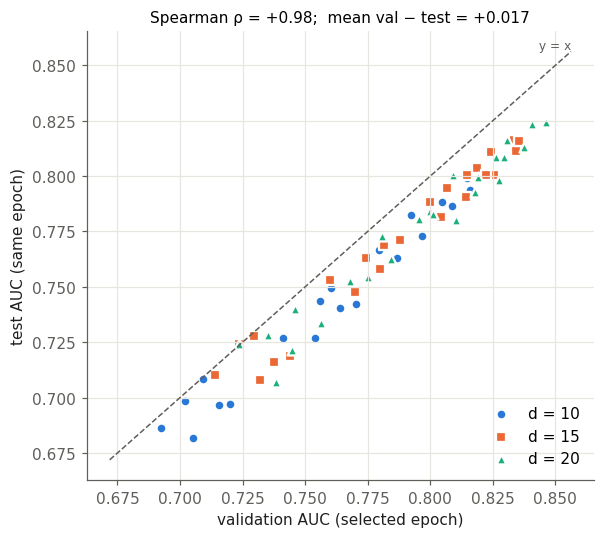

In [14]:
fig, ax = plt.subplots(figsize=(5.6, 5))
for d in (10, 15, 20):
    t = MT[MT.d == d]
    ax.scatter(t.val_auc, t.test_auc, color=D_COLOR[d], marker=D_MARK[d], s=42, edgecolor='white', linewidth=1.5, label=f'd = {d}')
lo, hi = MT[['val_auc', 'test_auc']].min().min() - 0.01, MT[['val_auc', 'test_auc']].max().max() + 0.01
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--'); ax.text(hi, hi, ' y = x', color=INK2, fontsize=8, va='bottom', ha='right')
ax.set_xlabel('validation AUC (selected epoch)'); ax.set_ylabel('test AUC (same epoch)')
ax.set_title(f'Spearman ρ = {spearmanr(MT.val_auc, MT.test_auc).statistic:+.2f};  '
             f'mean val − test = {(MT.val_auc - MT.test_auc).mean():+.3f}', fontsize=10)
ax.legend(loc='lower right'); fig.tight_layout(); plt.show()

### Agreement and reproduced programs vs test AUC (per setting)

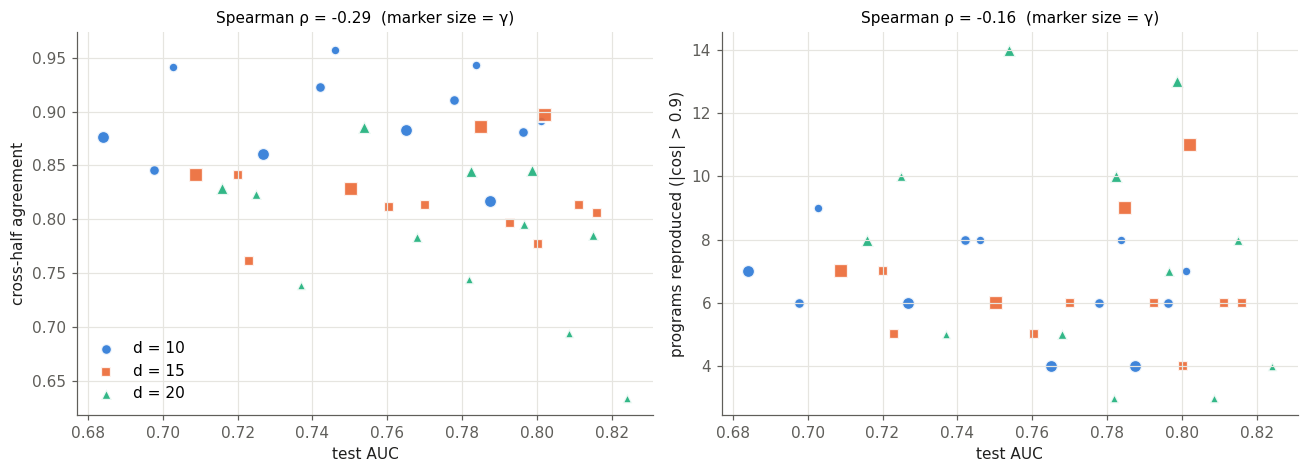

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
for ax, (ycol, lab) in zip(axes, [('agreement', 'cross-half agreement'), ('ax09', 'programs reproduced (|cos| > 0.9)')]):
    for d in (10, 15, 20):
        t = ST[ST.d == d]
        for g, edge in zip((0.0, 0.05, 0.15), (0.6, 1.2, 2.2)):
            tt = t[t.gamma == g]
            ax.scatter(tt.test_auc, tt[ycol], color=D_COLOR[d], marker=D_MARK[d], s=20 + 220 * g + 20, edgecolor='white',
                       linewidth=1.5, label=f'd = {d}' if g == 0.05 else None, alpha=0.9)
    ax.set_xlabel('test AUC'); ax.set_ylabel(lab)
    ax.set_title(f'Spearman ρ = {spearmanr(ST.test_auc, ST[ycol]).statistic:+.2f}  (marker size = γ)', fontsize=10)
axes[0].legend(loc='lower left'); fig.tight_layout(); plt.show()

### Test AUC against λ, per d and γ (validation AUC dashed)

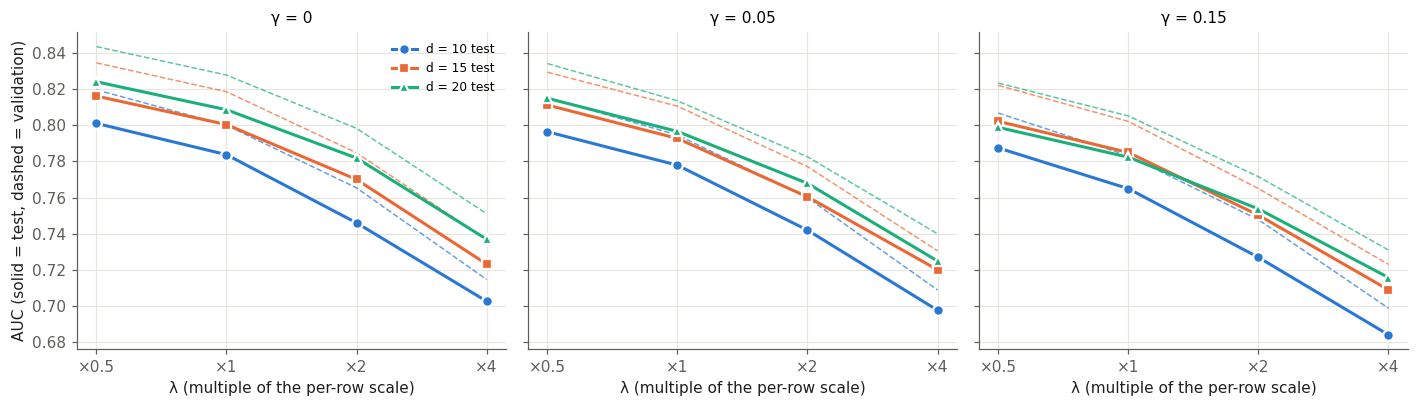

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, g in zip(axes, sorted(ST.gamma.unique())):
    for d in (10, 15, 20):
        t = ST[(ST.gamma == g) & (ST.d == d)].sort_values('lam_x')
        ax.plot(t.lam_x, t.test_auc, color=D_COLOR[d], marker=D_MARK[d], markeredgecolor='white', markeredgewidth=1.5, label=f'd = {d} test')
        ax.plot(t.lam_x, t.val_auc, color=D_COLOR[d], lw=1, ls='--', alpha=0.7)
    ax.set_xscale('log', base=2); ax.set_xticks([0.5, 1, 2, 4], ['×0.5', '×1', '×2', '×4'])
    ax.set_title(f'γ = {g:g}', fontsize=10); ax.set_xlabel('λ (multiple of the per-row scale)')
axes[0].set_ylabel('AUC (solid = test, dashed = validation)'); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Correlations including the test metrics

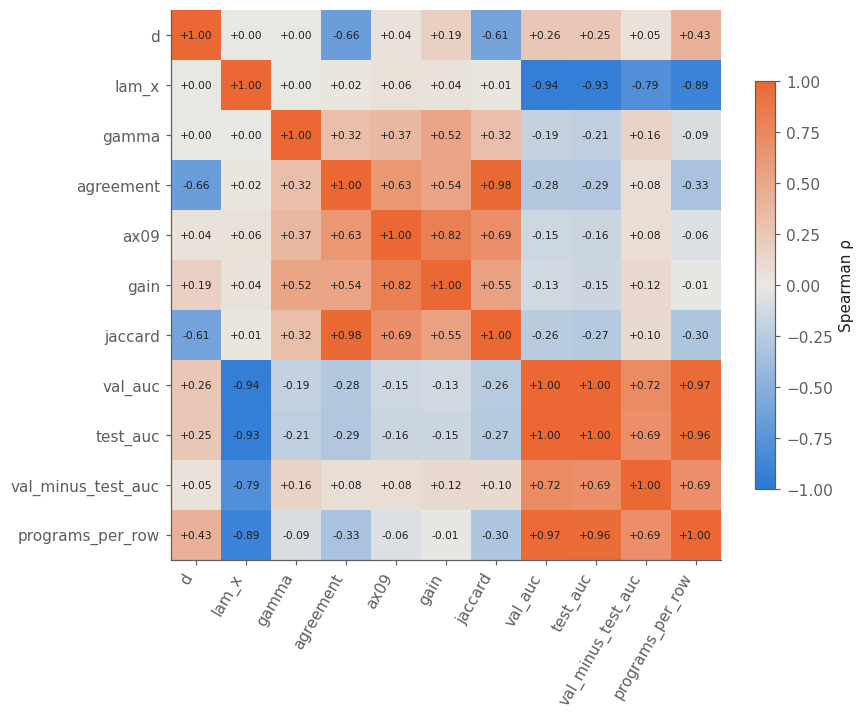

,d,lam_x,gamma,agreement,ax09,gain,jaccard,val_auc,test_auc,val_minus_test_auc,programs_per_row
d,1.00,0.00,0.00,-0.66,0.04,0.19,-0.61,0.26,0.25,0.05,0.43
lam_x,0.00,1.00,0.00,0.02,0.06,0.04,0.01,-0.94,-0.93,-0.79,-0.89
gamma,0.00,0.00,1.00,0.32,0.37,0.52,0.32,-0.19,-0.21,0.16,-0.09
agreement,-0.66,0.02,0.32,1.00,0.63,0.54,0.98,-0.28,-0.29,0.08,-0.33
ax09,0.04,0.06,0.37,0.63,1.00,0.82,0.69,-0.15,-0.16,0.08,-0.06
gain,0.19,0.04,0.52,0.54,0.82,1.00,0.55,-0.13,-0.15,0.12,-0.01
jaccard,-0.61,0.01,0.32,0.98,0.69,0.55,1.00,-0.26,-0.27,0.10,-0.30
val_auc,0.26,-0.94,-0.19,-0.28,-0.15,-0.13,-0.26,1.00,1.00,0.72,0.97
test_auc,0.25,-0.93,-0.21,-0.29,-0.16,-0.15,-0.27,1.00,1.00,0.69,0.96
val_minus_test_auc,0.05,-0.79,0.16,0.08,0.08,0.12,0.10,0.72,0.69,1.00,0.69


In [17]:
cols = ['d', 'lam_x', 'gamma', 'agreement', 'ax09', 'gain', 'jaccard', 'val_auc', 'test_auc', 'val_minus_test_auc', 'programs_per_row']
c2 = ST[cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(c2, cmap=div, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha='right'); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{c2.iloc[i, j]:+.2f}', ha='center', va='center', fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman ρ'); fig.tight_layout(); plt.show()
c2.round(2)